In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pumpkins= pd.read_csv("../data/US-pumpkins.csv")
pumpkins=pumpkins[pumpkins['Package'].str.contains('bushel',case=True,regex=True)]
pumpkins.head()
pumpkins.isnull().sum()


City Name            0
Type               406
Package              0
Variety              0
Sub Variety        167
Grade              415
Date                 0
Low Price            0
High Price           0
Mostly Low          24
Mostly High         24
Origin               0
Origin District    396
Item Size          114
Color              145
Environment        415
Unit of Sale       404
Quality            415
Condition          415
Appearance         415
Storage            415
Crop               415
Repack               0
Trans Mode         415
Unnamed: 24        415
Unnamed: 25        391
dtype: int64

In [21]:
columns_to_select=["Package","Low Price","High Price","Date"]
pumpkins.loc[:,columns_to_select]
price =(pumpkins["Low Price"]+pumpkins["High Price"])/2
month =pd.DatetimeIndex(pumpkins["Date"]).month
print(month)
print(price)

Index([ 9,  9, 10, 10, 10, 10, 10, 10, 10, 10,
       ...
        9,  9,  9,  9,  9,  9,  9,  9,  9,  9],
      dtype='int32', name='Date', length=415)
70      15.000
71      18.000
72      18.000
73      17.000
74      15.000
         ...  
1738    15.000
1739    14.375
1740    12.875
1741    12.000
1742    12.000
Length: 415, dtype: float64


In [22]:
new_pumpkins=pd.DataFrame({'Month':month,'Package':pumpkins['Package'],
'Low Price':pumpkins['Low Price'], 'High Price':pumpkins['High Price'],'Price':price})
new_pumpkins.loc[new_pumpkins['Package'].str.contains("1 1/9"),'Price']=price/(1+1/9)
new_pumpkins.loc[new_pumpkins['Package'].str.contains("1/2"),"Price"]=price/(1/2)
print(new_pumpkins)

      Month               Package  Low Price  High Price  Price
70        9  1 1/9 bushel cartons      15.00        15.0  13.50
71        9  1 1/9 bushel cartons      18.00        18.0  16.20
72       10  1 1/9 bushel cartons      18.00        18.0  16.20
73       10  1 1/9 bushel cartons      17.00        17.0  15.30
74       10  1 1/9 bushel cartons      15.00        15.0  13.50
...     ...                   ...        ...         ...    ...
1738      9    1/2 bushel cartons      15.00        15.0  30.00
1739      9    1/2 bushel cartons      13.75        15.0  28.75
1740      9    1/2 bushel cartons      10.75        15.0  25.75
1741      9    1/2 bushel cartons      12.00        12.0  24.00
1742      9    1/2 bushel cartons      12.00        12.0  24.00

[415 rows x 5 columns]


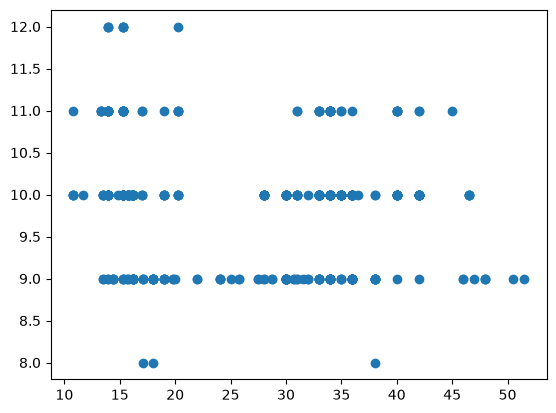

In [23]:
price = new_pumpkins.Price
month = new_pumpkins.Month
plt.scatter(price,month)
plt.show()

Text(0, 0.5, 'Pumpkin price')

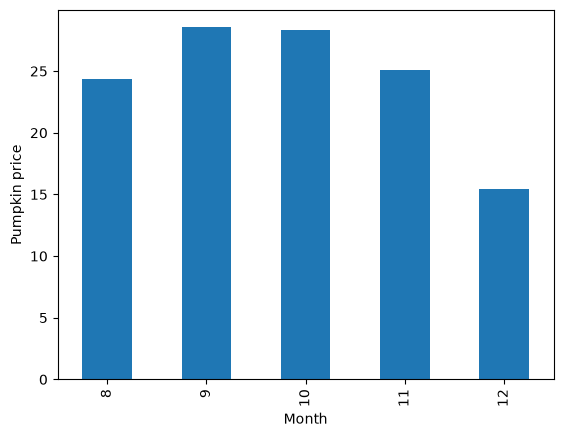

In [24]:
new_pumpkins.groupby(['Month'])['Price'].mean().plot(kind='bar')
plt.ylabel('Pumpkin price')

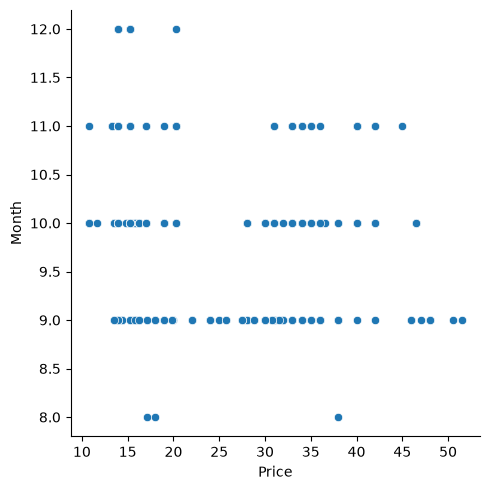

In [25]:
sns.relplot(x='Price',y='Month',data=new_pumpkins)

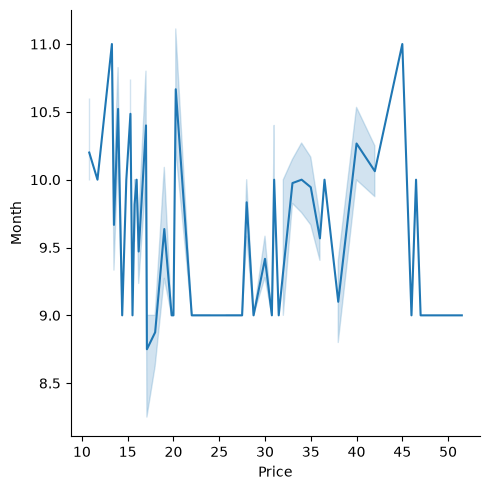

In [26]:
sns.relplot(x='Price',y='Month',kind='line',data=new_pumpkins)

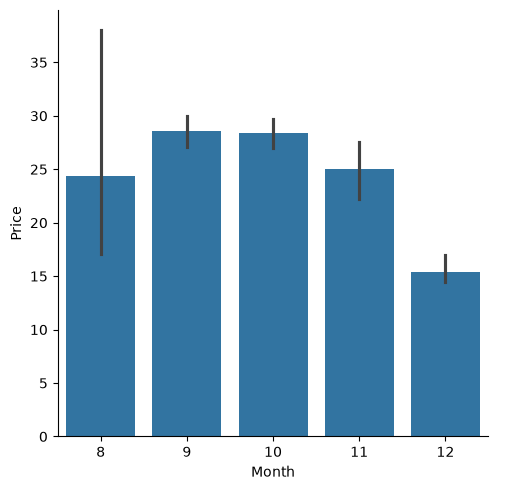

In [31]:
sns.catplot(x="Month",y="Price",kind="bar",data=new_pumpkins)

<Axes: >

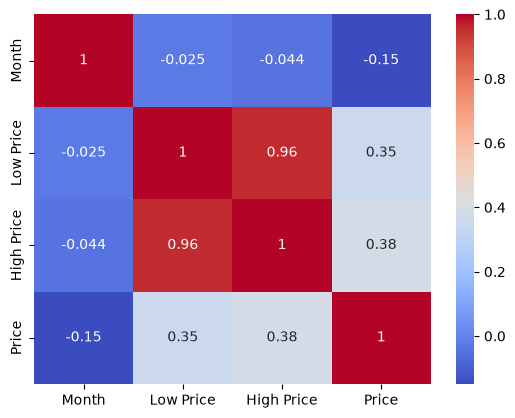

In [32]:
correlations = new_pumpkins[['Month','Low Price','High Price','Price']].corr()
sns.heatmap(correlations,annot=True,cmap="coolwarm")

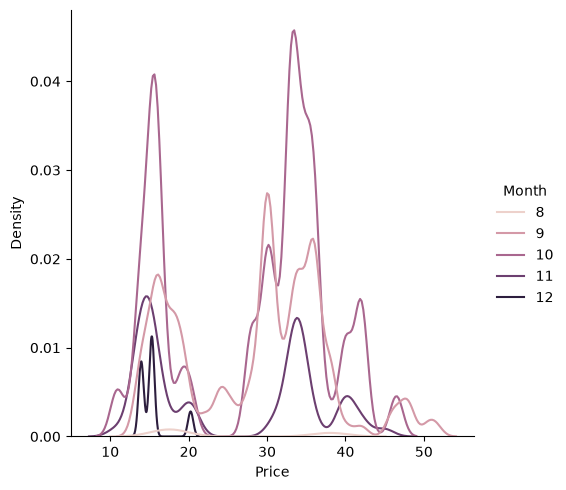

In [34]:
sns.displot(new_pumpkins,x='Price',kind='kde',hue='Month',bw_adjust=.25)

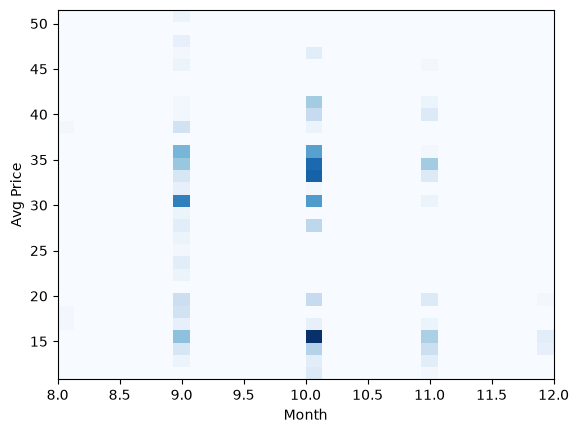

In [36]:
plt.hist2d(new_pumpkins['Month'],new_pumpkins['Price'],bins=30,cmap='Blues')
plt.xlabel('Month')
plt.ylabel('Avg Price')
plt.show()